In [17]:
# Import de Bibliotecas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq

## Questão 2

Os dados apresentados na tabela abaixo foram obtidos em condição de regime permanente com o objetivo de obter as curvas de permeabilidade relativa no escoamento bifásico de óleo e água.

*Dados adicionais obtidos nos experimentos:*  
Permeabilidade absoluta: K = 100 mD  
Diâmetro da amostra poroso: D = 3,2 cm  
Comprimento da amostra: L = 10 cm  
Porosidade da amostra: ∅ = 0.20  
Viscosidade da água: 𝜇𝑤 = 1.1 cP  
Viscosidade do óleo: 𝜇o = 5.0 cP  

In [11]:
df = pd.DataFrame({
    "Qo_cm3_h": [90, 75, 60, 45, 30, 15, 0],
    "Qa_cm3_h": [0, 5, 9, 20, 34, 85, 122],
    "dP_psi": [
        49.25, 91.29, 109.52, 123.30,
        137.05, 164.30, 147.00
    ],
    "Va_cm3": [2.17, 2.87, 3.63, 4.65, 5.93, 7.95, 9.86],
})

display(df)

,Qo_cm3_h,Qa_cm3_h,dP_psi,Va_cm3
0,90,0,49.25,2.17
1,75,5,91.29,2.87
2,60,9,109.52,3.63
3,45,20,123.30,4.65
4,30,34,137.05,5.93
5,15,85,164.30,7.95
6,0,122,147.00,9.86


In [12]:
## Utilitários de Unidades

# Conversões
MD_PARA_M2 = 9.869233e-16
PSI_PARA_PA = 6894.757293168
CM3H_PARA_M3S = 1e-6 / 3600



In [13]:
# Propriedades no SI
K = 100 * MD_PARA_M2   # m²
D = 3.2e-2            # m
L = 10e-2             # m
phi = 0.20

mu_a = 1.1e-3         # Pa.s
mu_o = 5.0e-3         # Pa.s

A = np.pi * D**2 / 4
V_poroso = phi * A * L

print(f"Volume poroso: {V_poroso * 1e6:.6f} cm³")

Volume poroso: 16.084954 cm³


In [14]:
# Converter os dados para o SI
df["Qo_m3_s"] = df["Qo_cm3_h"] * CM3H_PARA_M3S
df["Qa_m3_s"] = df["Qa_cm3_h"] * CM3H_PARA_M3S
df["dP_Pa"] = df["dP_psi"] * PSI_PARA_PA
df["Va_m3"] = df["Va_cm3"] * 1e-6

# Saturações
df["Sa"] = df["Va_m3"] / V_poroso
df["So"] = 1 - df["Sa"]

# Permeabilidades relativas
df["kra"] = (
    df["Qa_m3_s"] * mu_a * L
    / (K * A * df["dP_Pa"])
)

df["kro"] = (
    df["Qo_m3_s"] * mu_o * L
    / (K * A * df["dP_Pa"])
)

display(df.round(6))

,Qo_cm3_h,Qa_cm3_h,dP_psi,Va_cm3,Qo_m3_s,Qa_m3_s,dP_Pa,Va_m3,Sa,So,kra,kro
0,90,0,49.25,2.17,0.0,0.0,3.395668e+05,0.000002,0.134909,0.865091,0.000000,0.463780
1,75,5,91.29,2.87,0.0,0.0,6.294224e+05,0.000003,0.178428,0.821572,0.003058,0.208503
2,60,9,109.52,3.63,0.0,0.0,7.551138e+05,0.000004,0.225677,0.774323,0.004588,0.139038
3,45,20,123.30,4.65,0.0,0.0,8.501236e+05,0.000005,0.289090,0.710910,0.009057,0.092624
4,30,34,137.05,5.93,0.0,0.0,9.449265e+05,0.000006,0.368668,0.631332,0.013852,0.055554
5,15,85,164.30,7.95,0.0,0.0,1.132809e+06,0.000008,0.494251,0.505749,0.028885,0.023170
6,0,122,147.00,9.86,0.0,0.0,1.013529e+06,0.000010,0.612995,0.387005,0.046338,0.000000


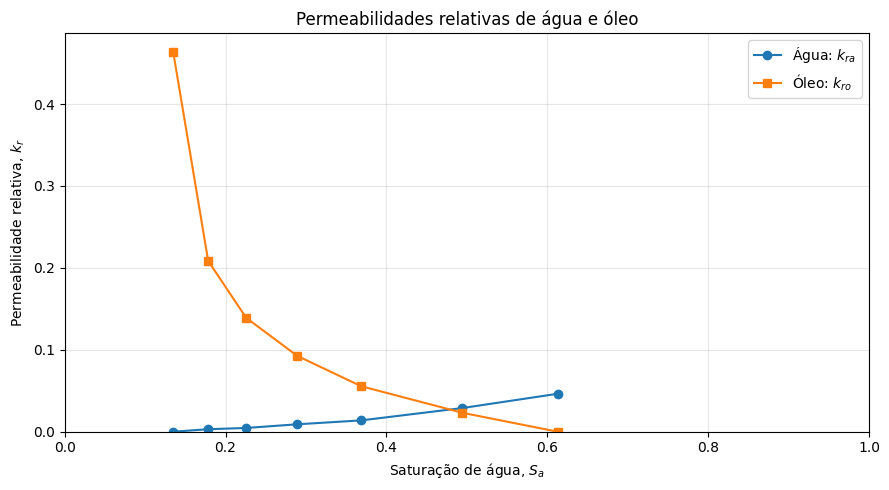

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    df["Sa"], df["kra"], "o-",
    label=r"Água: $k_{ra}$"
)

ax.plot(
    df["Sa"], df["kro"], "s-",
    label=r"Óleo: $k_{ro}$"
)

ax.set_xlabel(r"Saturação de água, $S_a$")
ax.set_ylabel(r"Permeabilidade relativa, $k_r$")
ax.set_title("Permeabilidades relativas de água e óleo")

ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Questão 3

Considere um meio poroso cilíndrico com raio 𝑟 = 5𝑐𝑚, comprimento 𝐿 = 40𝑐𝑚, permeabilidade de 𝐾 = 500 𝑚𝐷 e porosidade de ∅ = 20%. A saturação inicial de óleo é uniforme e igual a 𝑆𝑜 = 0.85; observe que a saturação de água é baixa o suficiente que a água residual existente no meio poroso não escoa.  
Água é injetada a uma vazão de 𝑄 = 1 𝑚𝑙/𝑠. A viscosidade do óleo é igual a 𝜇0 = 10𝑐𝑃 e a viscosidade da água é igual a 𝜇𝑤 = 1𝑐𝑃.    

Os dados de permeabilidade relativa em função da saturação de água do meio são apresentados na tabela
abaixo.  

Pede-se:
1. Construa um gráfico com as permeabilidades relativas dadas na tabela acima;
2. Desprezando o efeito de pressão capilar, determine a vazão fracional de água em função da saturação de água. Apresente o resultado em forma de uma tabela e um gráfico.
3. Determine a saturação de água na frente de propagação 𝑆𝑎.
4. Determine a velocidade de propagação da frente e o tempo de “breaktrough” da água.


In [19]:
df = pd.DataFrame({
    "Sw":  [0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80],
    "kro": [0.96, 0.69, 0.49, 0.33, 0.20, 0.11, 0.05, 0.00],
    "krw": [0.00, 0.005, 0.030, 0.070, 0.130, 0.190, 0.260, 0.350],
})

display(df)

,Sw,kro,krw
0,0.15,0.96,0.000
1,0.20,0.69,0.005
2,0.30,0.49,0.030
3,0.40,0.33,0.070
4,0.50,0.20,0.130
5,0.60,0.11,0.190
6,0.70,0.05,0.260
7,0.80,0.00,0.350


### Letra A

1. Construa um gráfico com as permeabilidades relativas dadas na tabela acima;

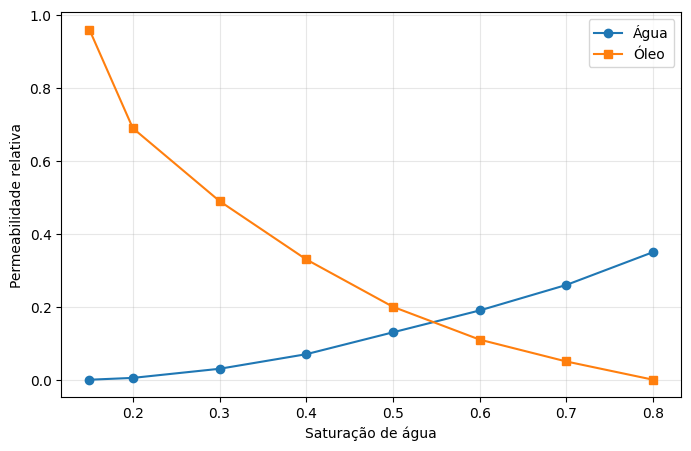

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(df["Sw"], df["krw"], "o-", label="Água")
plt.plot(df["Sw"], df["kro"], "s-", label="Óleo")

plt.xlabel("Saturação de água")
plt.ylabel("Permeabilidade relativa")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Letra B

2. Desprezando o efeito de pressão capilar, determine a vazão fracional de água em função da saturação de água. Apresente o resultado em forma de uma tabela e um gráfico.

A definição é:

$$
f_w = \frac{Q_w}{Q_w + Q_o}.
$$

Utilizando a lei de Darcy com o mesmo gradiente de pressão para ambas as fases:

$$
Q_w = \frac{KA}{L}\frac{k_{rw}}{\mu_w}\Delta P,
\qquad
Q_o = \frac{KA}{L}\frac{k_{ro}}{\mu_o}\Delta P.
$$

Substituindo na definição e cancelando o fator comum $KA\Delta P/L$:

$$
f_w(S_w) =
\frac{k_{rw}/\mu_w}
{k_{rw}/\mu_w + k_{ro}/\mu_o}
$$

O que permite calcular $f_w$ em função de $S_w$.

In [24]:
# Geometria e vazão no SI
r = 0.05       # m
L = 0.40       # m
phi = 0.20
Q = 1e-6       # m³/s

# Viscosidades na mesma unidade
mu_w = 1e-3    # Pa.s
mu_o = 10e-3   # Pa.s

Swi = 0.15
A = np.pi * r**2

,Sw,kro,krw,fw
0,0.15,0.96,0.000,0.000000
1,0.20,0.69,0.005,0.067568
2,0.30,0.49,0.030,0.379747
3,0.40,0.33,0.070,0.679612
4,0.50,0.20,0.130,0.866667
5,0.60,0.11,0.190,0.945274
6,0.70,0.05,0.260,0.981132
7,0.80,0.00,0.350,1.000000


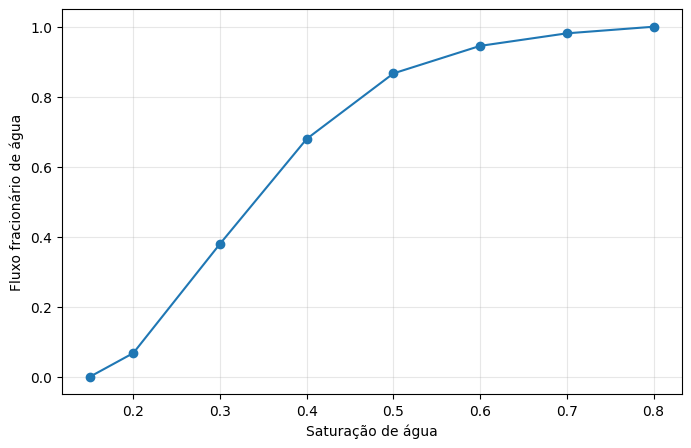

In [25]:
df["fw"] = (
    (df["krw"] / mu_w)
    / (df["krw"] / mu_w + df["kro"] / mu_o)
)

display(df.round(6))

plt.figure(figsize=(8, 5))
plt.plot(df["Sw"], df["fw"], "o-")

plt.xlabel("Saturação de água")
plt.ylabel("Fluxo fracionário de água")
plt.grid(alpha=0.3)
plt.show()

In [26]:
krw = PchipInterpolator(df["Sw"], df["krw"], extrapolate=False)
kro = PchipInterpolator(df["Sw"], df["kro"], extrapolate=False)

dkrw = krw.derivative()
dkro = kro.derivative()

def fw(Sw):
    lw = krw(Sw) / mu_w
    lo = kro(Sw) / mu_o
    return lw / (lw + lo)

def dfw(Sw):
    lw = krw(Sw) / mu_w
    lo = kro(Sw) / mu_o

    dlw = dkrw(Sw) / mu_w
    dlo = dkro(Sw) / mu_o

    return (dlw * lo - lw * dlo) / (lw + lo)**2

fw_i = float(fw(Swi))

def condicao_frente(Sw):
    return dfw(Sw) - (fw(Sw) - fw_i) / (Sw - Swi)

Swf = brentq(condicao_frente, 0.30, 0.50)

fw_f = float(fw(Swf))
m = (fw_f - fw_i) / (Swf - Swi)

print(f"Sw da frente = {Swf:.6f}")
print(f"fw na frente = {fw_f:.6f}")
print(f"Inclinação da tangente = {m:.6f}")

Sw da frente = 0.378514
fw na frente = 0.624043
Inclinação da tangente = 2.730875


In [27]:
v_frente = Q / (phi * A) * m
t_bt = L / v_frente

print(f"Velocidade da frente: {v_frente * 100:.6f} cm/s")
print(f"Breakthrough: {t_bt:.2f} s")
print(f"Breakthrough: {t_bt / 60:.2f} min")

Velocidade da frente: 0.173853 cm/s
Breakthrough: 230.08 s
Breakthrough: 3.83 min
